# 07 · Q4 — Berapa minggu sebelum Idulfitri harga mulai naik, dan seberapa besar?

**Keputusan yang didukung:** kapan membeli stok sebelum musim lonjakan.

**Metode** (event study, `src/analysis/seasonality.py`, `config.analisis.q4_musiman`):
- Tanggal Idulfitri dari SKB libur nasional (`data/reference/hari_besar.csv`): 2024-04-10, 2025-03-31, 2026-03-21.
- Harga normal = rata-rata minggu −12 s/d −9; kenaikan = harga minggu w / harga normal − 1, untuk w = −8 … +4.
- Dihitung per kota × tahun, diringkas dengan median antar kota, lalu ditampilkan **per tahun** (bukan hanya rata-rata).
- "Mulai naik" = setiap minggu sejak itu sampai minggu −1 ≥ 5% di atas normal pada ≥ 2 dari 3 tahun.

**Batasan:** hanya 3 kali Idulfitri; minggu Lebaran 2024 & 2025 tanpa pencatatan (libur); musim panen/hujan bisa
bercampur dengan efek Lebaran.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import seasonality as SE
res = SE.run(cfg)
res["ringkas"][["kualitas", "mulai_naik_minggu", "mulai_di_batas_jendela", "tahun_konsisten", "kenaikan_minggu_min1_rata",
                "kenaikan_minggu_min1_per_tahun", "puncak_minggu", "puncak_kenaikan_rata", "kenaikan_minggu_plus4_rata"]]

,kualitas,mulai_naik_minggu,mulai_di_batas_jendela,tahun_konsisten,kenaikan_minggu_min1_rata,kenaikan_minggu_min1_per_tahun,puncak_minggu,puncak_kenaikan_rata,kenaikan_minggu_plus4_rata
0,Cabai Rawit Merah,-8.000,True,2 dari 3,0.388,2024: -13%; 2025: +18%; 2026: +112%,-5,0.560,-0.183
1,Cabai Merah Keriting,NaN,False,1 dari 3,-0.024,2024: -36%; 2025: -5%; 2026: +33%,0,0.124,-0.066
2,Bawang Merah Ukuran Sedang,-4.000,False,3 dari 3,0.256,2024: +25%; 2025: +39%; 2026: +13%,2,0.528,0.308
3,Bawang Putih Ukuran Sedang,NaN,False,1 dari 3,0.024,2024: +4%; 2025: +5%; 2026: -2%,1,0.064,0.028
4,Daging Ayam Ras Segar,-6.000,False,2 dari 3,0.106,2024: +16%; 2025: +0%; 2026: +16%,0,0.201,0.000
5,Telur Ayam Ras Segar,NaN,False,1 dari 3,0.033,2024: +5%; 2025: -0%; 2026: +5%,-4,0.108,0.027


## 1. Pola per komoditas, dengan rentang antar tahun

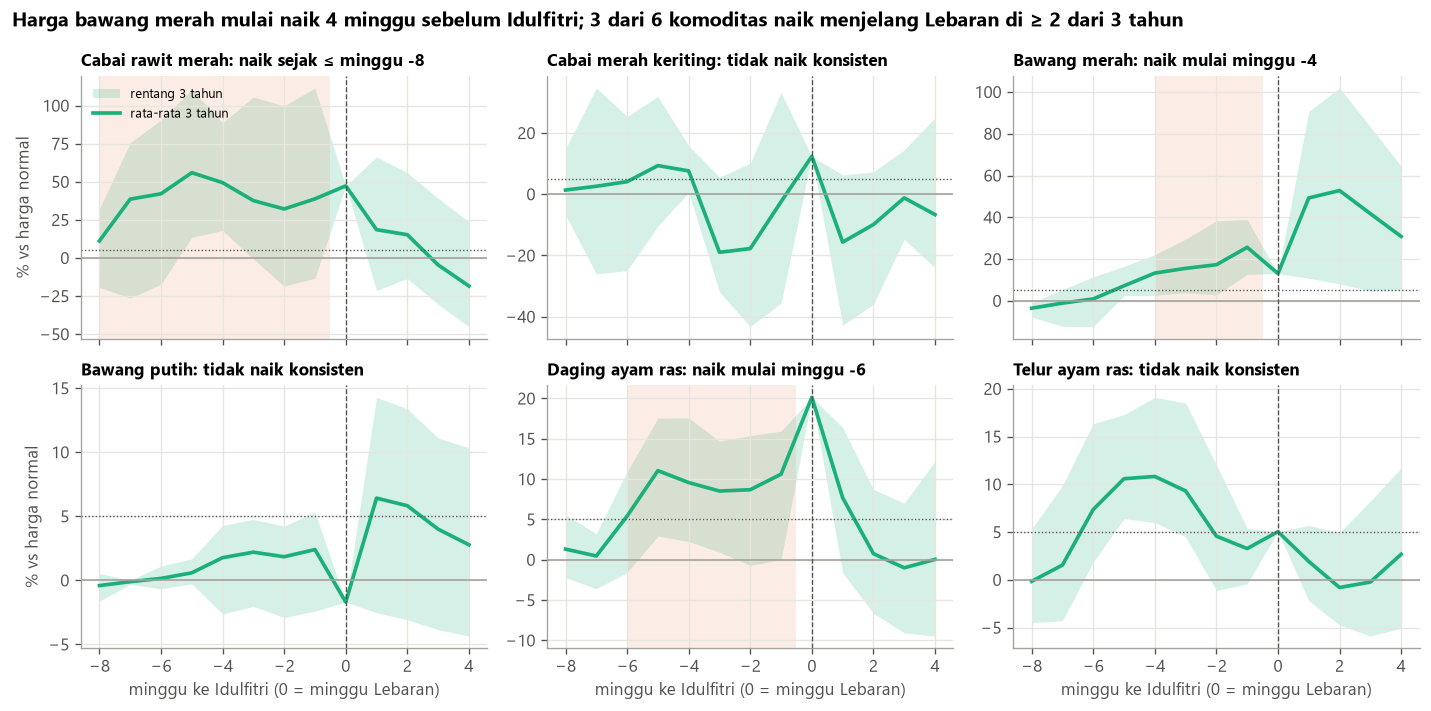

In [2]:
figs = SE.figures(res, cfg)
gambar(figs["pola"])

## 2. Variasi antar tahun
Rata-rata 3 tahun bisa menutupi perbedaan besar antar tahun. Tabel di bawah: median kenaikan antar kota per tahun.

In [3]:
for kom in ["Bawang Merah Ukuran Sedang", "Cabai Rawit Merah", "Daging Ayam Ras Segar"]:
    t = res["per_tahun"][res["per_tahun"].kualitas == kom].pivot(index="tahun_idul_fitri", columns="minggu_ke_idul_fitri",
                                                               values="kenaikan_median_kota")
    print(kom)
    display(t.loc[:, -8:4].round(2))

Bawang Merah Ukuran Sedang


minggu_ke_idul_fitri,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4
tahun_idul_fitri,,,,,,,,,,,,,
2024,-0.020,0.040,0.040,0.030,0.030,0.040,0.030,0.250,NaN,0.910,1.020,0.830,0.650
2025,-0.080,-0.120,-0.120,0.020,0.220,0.300,0.380,0.390,NaN,0.460,0.480,0.370,0.230
2026,-0.010,0.050,0.110,0.160,0.150,0.130,0.110,0.130,0.130,0.110,0.080,0.050,0.050


Cabai Rawit Merah


minggu_ke_idul_fitri,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4
tahun_idul_fitri,,,,,,,,,,,,,
2024,0.320,0.760,0.530,0.440,0.420,-0.010,-0.180,-0.130,NaN,-0.210,-0.130,-0.220,-0.340
2025,-0.190,-0.260,-0.170,0.140,0.180,0.080,0.150,0.180,NaN,0.110,0.030,-0.300,-0.450
2026,0.210,0.670,0.910,1.110,0.890,1.060,1.000,1.120,0.470,0.660,0.560,0.390,0.240


Daging Ayam Ras Segar


minggu_ke_idul_fitri,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4
tahun_idul_fitri,,,,,,,,,,,,,
2024,0.060,0.030,0.070,0.180,0.180,0.150,0.150,0.160,NaN,0.160,0.090,0.070,0.120
2025,-0.020,-0.040,-0.020,0.030,0.020,0.010,-0.010,0.000,NaN,-0.020,-0.070,-0.090,-0.090
2026,0.010,0.020,0.110,0.130,0.090,0.100,0.110,0.160,0.200,0.080,0.000,-0.010,-0.030


## 3. Cara membaca "≥ 8 minggu"
Jika syarat "mulai naik" sudah terpenuhi sejak minggu −8 (awal jendela), awal kenaikan sebenarnya bisa lebih awal;
hasilnya ditulis "≥ 8 minggu" dan disertai jumlah tahun yang konsisten, bukan angka tunggal yang tampak presisi.

### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [4]:
SE.write_summary(res, figs, cfg)
tampilkan_temuan("q4_pola_idul_fitri.md")

**Harga bawang merah mulai naik 4 minggu sebelum Idulfitri, jadi stok perlu diamankan sebelum itu.** Seminggu sebelum Lebaran harganya rata-rata +26% dibanding harga normal (minggu −12 s/d −9). Komoditas lain yang naik konsisten: cabai rawit merah (≥ 8 minggu sebelum (sejak awal jendela), naik di 2 dari 3 tahun), daging ayam ras (6 minggu sebelum, naik di 2 dari 3 tahun).
Tidak naik konsisten: cabai merah keriting, bawang putih, telur ayam ras.
Pola ini masih perkiraan kasar karena baru ada 3 kali Idulfitri dalam data.